# Классификация изображений с YOLO

Intel Image Dataset содержит 3000 изображений шести классов: здания, лес, ледники, горы, море и улицы.  
Задача классифицировать изображения с помощью transfer learning на основе предобученной модели YOLO26s-cls.

Подключим библиотеки.

In [3]:
from pathlib import Path
import random
import csv
import shutil

import kagglehub
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

Скачаем датасет.

In [2]:
root = Path(kagglehub.dataset_download("rahmasleam/intel-image-dataset", output_dir="data/intel"))
print(root)


data\intel


Посчитаем изображения каждого класса.

In [3]:
images_dir = root / "Intel Image Dataset"
classes = sorted(folder.name for folder in images_dir.iterdir() if folder.is_dir())
print(classes)
print({name: len(list((images_dir / name).glob("*.jpg"))) for name in classes})


['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
{'buildings': 437, 'forest': 474, 'glacier': 553, 'mountain': 525, 'sea': 510, 'street': 501}


Посмотрим примеры изображений.

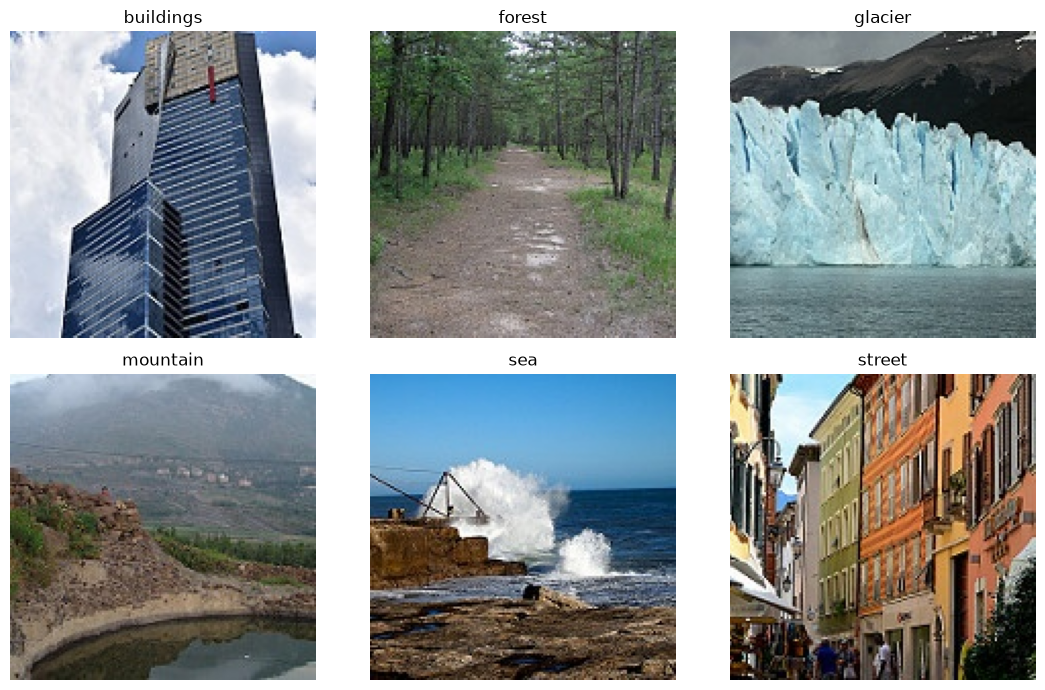

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, name in zip(axes.flat, classes):
    image_path = next((images_dir / name).glob("*.jpg"))
    ax.imshow(Image.open(image_path))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()


Разделим каждый класс: 70% для обучения, 15% для валидации и 15% для теста.

In [5]:
random.seed(42)
data_dir = Path("data/intel_train_val_test")
for name in classes:
    images = sorted((images_dir / name).glob("*.jpg"))
    random.shuffle(images)
    for i, image in enumerate(images):
        split = "train" if i < int(0.7 * len(images)) else "val" if i < int(0.85 * len(images)) else "test"
        folder = data_dir / split / name
        folder.mkdir(parents=True, exist_ok=True)
        shutil.copy2(image, folder / image.name)

Обучим модель на 30 эпохах с исходных предобученных весов YOLO.

In [6]:
model = YOLO("yolo26s-cls.pt")
results = model.train(data=str(data_dir), epochs=30, imgsz=224, batch=32, device=0,
                      workers=0, seed=42, patience=0, save_period=1, project="runs", name="intel_test")

Overriding model.yaml nc=1000 with nc=6



30 epochs completed in 0.068 hours.


Посмотрим ошибку на обучающей и валидационной выборках.

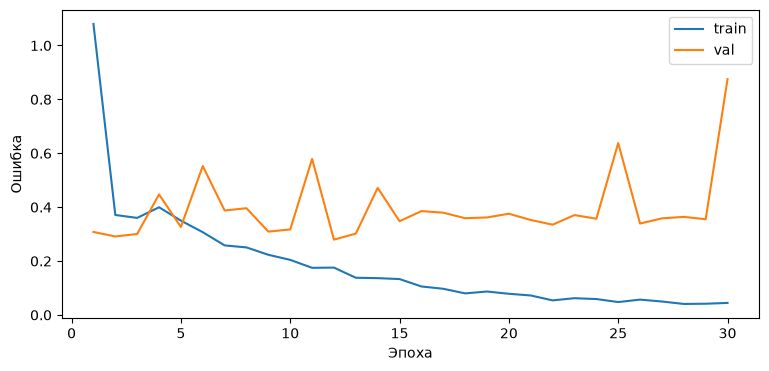

In [7]:
run_dir = Path(model.trainer.save_dir)
with (run_dir / "results.csv").open() as file:
    history = list(csv.DictReader(file))
epochs = [int(row["epoch"]) for row in history]
plt.figure(figsize=(9, 4))
plt.plot(epochs, [float(row["train/loss"]) for row in history], label="train")
plt.plot(epochs, [float(row["val/loss"]) for row in history], label="val")
plt.xlabel("Эпоха")
plt.ylabel("Ошибка")
plt.legend()
plt.show()

Для дальнейшей проверки выберем веса 26-й эпохи мне они нравятся больше всего

In [8]:
selected_epoch = 26
model = YOLO(str(run_dir / "weights" / f"epoch{selected_epoch - 1}.pt"))
metrics = model.val(data=str(data_dir), split="test", device=0, plots=True)
print(f"Верно распознано на тестовой выборке: {metrics.top1:.1%}")

Верно распознано на тестовой выборке: 93.6%


Посмотрим, какие классы модель путает.

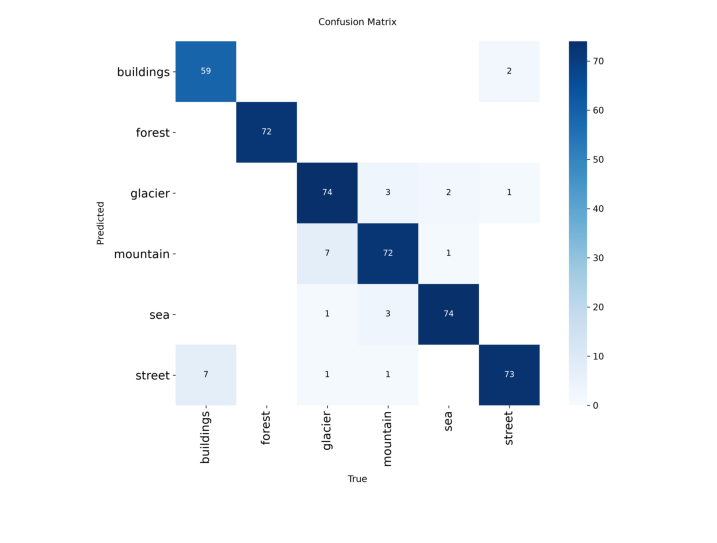

In [9]:
plt.figure(figsize=(9, 7))
plt.imshow(Image.open(Path(metrics.save_dir) / "confusion_matrix.png"))
plt.axis("off")
plt.show()

Посмотрим шесть ошибочных предсказаний.

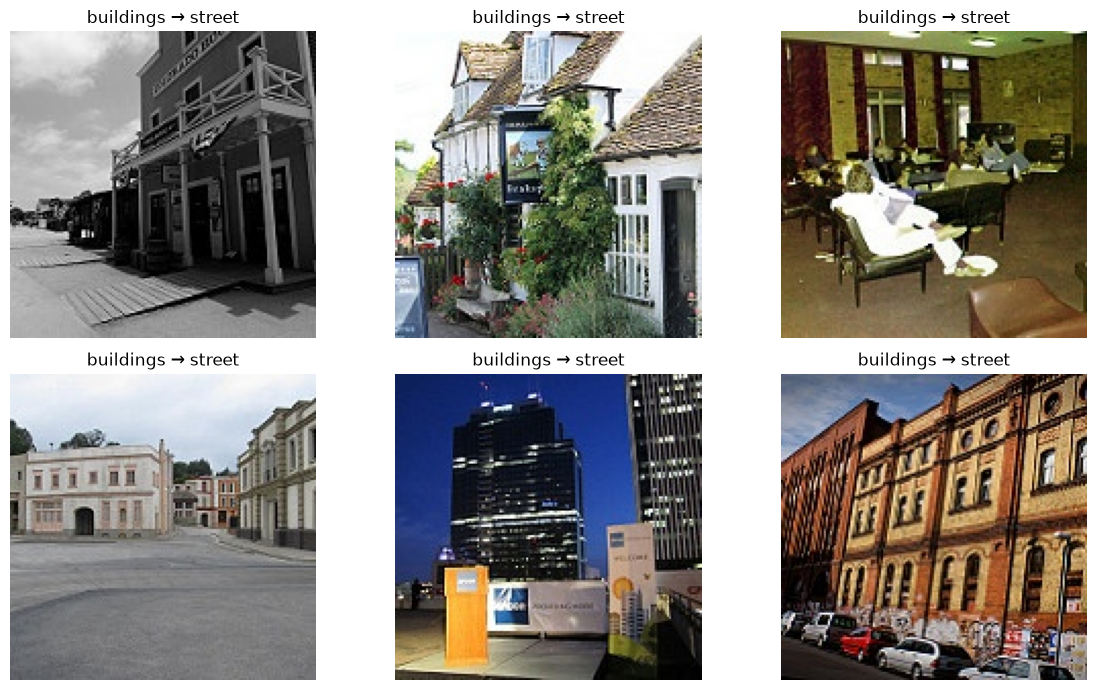

In [10]:
images = sorted((data_dir / "test").glob("*/*.jpg"))
predictions = model.predict([str(p) for p in images], batch=32, device=0, verbose=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
i = 0
for path, result in zip(images, predictions):
    predicted = result.names[result.probs.top1]
    if predicted != path.parent.name:
        axes.flat[i].imshow(Image.open(path))
        axes.flat[i].set_title(f"{path.parent.name} → {predicted}")
        axes.flat[i].axis("off")
        i += 1
        if i == 6:
            break
plt.tight_layout()
plt.show()